# 総研大 2024年度 講義「シミュレーション天文学」 / SOKEN-dai FY2024 Lecture Course: “Simulation Astronomy”
### 担当：馬場淳一 (国立天文台 科学研究部/鹿児島大学 天の川銀河研究センター) / Junichi Baba (D. of Science, NAOJ / Kagoshima University)

This code is provided for educational purposes only. Users are encouraged to utilize it at their own risk. I take no responsibility for any results obtained from research or analyses conducted using this code. It is essential to deepen your understanding and verify the results independently. Additionally, it is recommended to cross-reference with other reliable resources to ensure the appropriate methodologies are applied.

このコードは教育目的で提供されています。使用にあたっては、自己責任で行ってください。提供されたコードを基に行った研究や解析によって得られた結果について、私は一切の責任を負いません。使用する際には、必ず自身の理解を深め、結果を検証してください。また、他の信頼できるリソースと照らし合わせて、適切な方法論を選択することをお勧めします。

## 学習目標と計算上の前提

古典RK4は大域4次精度です。小さい刻みでは丸め誤差により収束曲線が飽和します。高次精度と長時間の保存則は異なる性質です。解析解の比較例は t0=0, y0=1 です。

検証課題と判定基準は [演習ガイド](../docs/exercises.md) を参照してください。


このNotebookでは線形自律方程式 $y'=-\alpha y$ を比較します。この問題ではHeun法と陽的中点法の更新多項式が同じなので、図の曲線は丸め誤差を除き重なります。一般の非線形問題で同じ方法になるわけではありません。


In [1]:
import numpy as np
import time 
import matplotlib.pyplot as plt
import matplotlib.cm as cm
parameters = {
    'axes.labelsize': 26,           # Set the font size of the x-axis and y-axis labels to 26
    'xtick.labelsize': 24,          # Set the font size of the x-axis tick labels to 24
    'ytick.labelsize': 24,          # Set the font size of the y-axis tick labels to 24
    'axes.titlesize': 24,           # Set the font size of the axis titles (not the overall graph title) to 24
    'figure.titlesize': 24,         # Set the font size of the overall graph title to 24
    'legend.fontsize': 22,          # Set the font size of the legend to 22
    'figure.figsize': [10, 6],      # Set the default figure size (width 10 inches, height 6 inches)
    'axes.linewidth': 2.0           # Set the linewidth of the axes
}
plt.rcParams.update(parameters)


In [2]:
def f(t, y, alpha):
    """
    Defines the right-hand side of the differential equation dy/dt = -alpha * y.

    Parameters:
        t (float): The current time
        y (float): The current value of y
        alpha (float): The coefficient alpha in the equation

    Returns:
        float: The value of dy/dt
    """
    return -alpha * y

def analytical_solution(t, alpha):
    """
    Computes the analytical solution y(t) = e^(-alpha * t).

    Parameters:
        t (float or np.ndarray): The time at which to evaluate the solution
        alpha (float): The coefficient alpha in the equation

    Returns:
        float or np.ndarray: The analytical solution y(t)
    """
    return np.exp(-alpha * t)


## 前進Euler法の復習

更新式と説明は [ex01](ex01%20euler_accuracy.ipynb) を参照してください。以下では比較のため同じ実装を定義します。


In [3]:
# Define the Forward Euler Method Function
def euler_method(f, y0, t0, t_end, h, alpha):
    """
    Solve the ODE dy/dt = f(t, y) using the explicit Forward Euler method.

    Parameters:
        f (callable): Function representing dy/dt = f(t, y)
        y0 (float): Initial condition y(t0) = y0
        t0 (float): Initial time
        t_end (float): End time
        h (float): Step size
        alpha (float): Parameter in the ODE

    Returns:
        t_values (numpy.ndarray): Array of time points
        y_values (numpy.ndarray): Array of numerical solutions at each time point
    """
    if not (np.isfinite(h) and h > 0 and np.isfinite(t0) and np.isfinite(t_end) and t_end > t0):
        raise ValueError("Require finite t_end > t0 and h > 0")
    N = max(1, int(round((t_end - t0) / h)))
    h = (t_end - t0) / N  # Actual uniform step matches returned times
    t_values = np.linspace(t0, t_end, N + 1)
    y_values = np.zeros(N + 1)
    y_values[0] = y0

    for n in range(N):
        t_n = t_values[n]
        y_n = y_values[n]
        y_new = y_n + h * f(t_n, y_n, alpha)
        y_values[n + 1] = y_new

    return t_values, y_values


## Heun法の復習

式と説明は [ex02](ex02%20rk2_accuracy.ipynb) を参照してください。以下では比較用にHeun法を定義します。


In [4]:
def rk2_heun_method(f, y0, t0, t_end, h, alpha):
    """
    Solve the ODE dy/dt = f(t, y) using Heun's method (explicit trapezoidal method).

    Parameters:
        f (callable): Function representing dy/dt = f(t, y, alpha)
        y0 (float): Initial condition y(t0) = y0
        t0 (float): Initial time
        t_end (float): End time
        h (float): Step size
        alpha (float): Parameter in the ODE

    Returns:
        t_values (numpy.ndarray): Array of time points
        y_values (numpy.ndarray): Array of numerical solutions at each time point
    """
    if not (np.isfinite(h) and h > 0 and np.isfinite(t0) and np.isfinite(t_end) and t_end > t0):
        raise ValueError("Require finite t_end > t0 and h > 0")
    N = max(1, int(round((t_end - t0) / h)))
    h = (t_end - t0) / N  # Actual uniform step matches returned times
    t_values = np.linspace(t0, t_end, N + 1)
    y_values = np.zeros(N + 1)
    y_values[0] = y0

    for n in range(N):
        t_n = t_values[n]
        y_n = y_values[n]

        # Predictor step (Forward Euler)
        y_predictor = y_n + h * f(t_n, y_n, alpha)

        # Corrector step (average slope)
        t_new = t_n + h
        y_corrector = y_n + (h / 2) * (f(t_n, y_n, alpha) + f(t_new, y_predictor, alpha))

        y_values[n + 1] = y_corrector

    return t_values, y_values


## 陽的中点法の復習

式とHeun法との違いは [ex02](ex02%20rk2_accuracy.ipynb) を参照してください。以下では比較用に陽的中点法を定義します。


In [5]:
def rk2_midpoint_method(f, y0, t0, t_end, h, alpha):
    """
    Solve the ODE dy/dt = f(t, y) using the RK2 method (midpoint method).

    Parameters:
        f (callable): Function representing dy/dt = f(t, y, alpha)
        y0 (float): Initial condition y(t0) = y0
        t0 (float): Initial time
        t_end (float): End time
        h (float): Step size
        alpha (float): Parameter in the ODE

    Returns:
        t_values (numpy.ndarray): Array of time points
        y_values (numpy.ndarray): Array of numerical solutions at each time point
    """
    if not (np.isfinite(h) and h > 0 and np.isfinite(t0) and np.isfinite(t_end) and t_end > t0):
        raise ValueError("Require finite t_end > t0 and h > 0")
    N = max(1, int(round((t_end - t0) / h)))
    h = (t_end - t0) / N  # Actual uniform step matches returned times
    t_values = np.linspace(t0, t_end, N + 1)
    y_values = np.zeros(N + 1)
    y_values[0] = y0

    for n in range(N):
        t_n = t_values[n]
        y_n = y_values[n]

        # Predictor step (Euler's step to midpoint)
        k1 = f(t_n, y_n, alpha)
        y_mid = y_n + (h / 2) * k1  # Midpoint value

        # Corrector step (use slope at the midpoint)
        k2 = f(t_n + h / 2, y_mid, alpha)
        y_new = y_n + h * k2  # Update using the slope at midpoint

        y_values[n + 1] = y_new

    return t_values, y_values


# Classical Runge-Kutta (RK4) Method Explanation

### Objective
The **Classical Runge-Kutta Method**, often referred to as the **RK4 Method**, is a fourth-order numerical technique for solving **ordinary differential equations (ODEs)**. It provides a significant improvement in accuracy over simpler methods like the **Euler Method** or **Modified Euler Method** by using multiple intermediate steps to estimate the slope. The RK4 method is widely used due to its balance between accuracy and computational efficiency.

### Key Equation

For a general initial value problem:

$$
\frac{dy}{dt} = f(t, y), \quad y(t_0) = y_0
$$

where $y(t)$ is the unknown function, $t$ is the independent variable (often representing time), and $f(t, y)$ is the derivative of $y$ with respect to $t$.

The **RK4 Method** uses the following formula to estimate $y$ at each step:

$$
y_{n+1} = y_n + \frac{h}{6} (k_1 + 2k_2 + 2k_3 + k_4)
$$

Where:
- $h$ is the step size (time increment).
- $k_1, k_2, k_3, k_4$ are the intermediate slope estimates:
  $$
  k_1 = f(t_n, y_n)
  $$
  $$
  k_2 = f\left(t_n + \frac{h}{2}, y_n + \frac{h}{2} k_1\right)
  $$
  $$
  k_3 = f\left(t_n + \frac{h}{2}, y_n + \frac{h}{2} k_2\right)
  $$
  $$
  k_4 = f(t_n + h, y_n + h k_3)
  $$
- $y_{n+1}$ is the value of $y$ at the next time step.

### Step-by-Step Procedure

1. **Initialization**:
   - Start with an initial condition: $y(t_0) = y_0$.
   - Set the step size $h$ and define the time range over which you want to compute the solution.

2. **Intermediate Steps**:
   - Calculate the four intermediate slopes $k_1, k_2, k_3, k_4$ using the formulas above.

3. **Update**:
   - Compute the next value of $y$ using:
     $$
     y_{n+1} = y_n + \frac{h}{6} (k_1 + 2k_2 + 2k_3 + k_4)
     $$

4. **Iteration**:
   - Repeat the process for each time step until the desired time range is covered.

### Advantages
- **High Accuracy**: The RK4 method is a fourth-order method, meaning the error decreases at a rate proportional to $h^4$, making it significantly more accurate than first or second-order methods.
- **Good Balance of Efficiency and Accuracy**: It is widely used because it offers a good balance between computational cost and accuracy, making it suitable for many practical problems.

### Disadvantages
- **More Computationally Intensive**: The method requires four function evaluations per step, which increases the computational cost compared to simpler methods like the Euler Method.
- **Fixed Step Size**: In its classical form, the RK4 method uses a fixed step size, which may not be ideal for problems where adaptive step sizing is necessary.

## Explanation of the `rk4_method` Function

This function implements the **4th-order Runge-Kutta (RK4) method**, which is a highly accurate method for solving ordinary differential equations (ODEs) of the form $ \frac{dy}{dt} = f(t, y) $. The RK4 method improves upon lower-order methods by using four function evaluations per step to achieve higher accuracy.

### Function Parameters:
- **`f` (callable)**: The ODE function representing $ f(t, y, \alpha) $, where $ \alpha $ is a parameter of the ODE.
- **`y0` (float)**: The initial condition, representing $ y(t_0) = y_0 $.
- **`t0` (float)**: The starting time.
- **`t_end` (float)**: The end time of the simulation.
- **`h` (float)**: The step size for time discretization.
- **`alpha` (float)**: A parameter of the ODE that influences the behavior of $ f $.

### Returns:
- **`t_values` (numpy.ndarray)**: An array containing the time points from $ t_0 $ to $ t_{\text{end}} $.
- **`y_values` (numpy.ndarray)**: An array containing the numerical solution for $ y $ at each time point.

### Key Steps in the Code:

1. **Time and Solution Arrays Initialization**:
   - The number of steps $ N $ is calculated based on the total simulation time and the step size.
   - The `t_values` array holds the time points, and `y_values` stores the corresponding $ y $-values.
   - The initial condition $ y_0 $ is assigned to `y_values[0]`.

2. **Main Loop for Time Stepping**:
   - For each time step $ n $, the current time $ t_n $ and the corresponding solution $ y_n $ are retrieved.

3. **RK4 Coefficients**:
   - The RK4 method calculates four intermediate slopes (coefficients) $ k_1, k_2, k_3, k_4 $ at different points within the time step:
     - $ k_1 $ is the slope at the beginning of the step:
       $$
       k_1 = f(t_n, y_n, \alpha)
       $$
     - $ k_2 $ is the slope at the midpoint, using the first slope $ k_1 $:
       $$
       k_2 = f(t_n + \frac{h}{2}, y_n + \frac{h}{2} \cdot k_1, \alpha)
       $$
     - $ k_3 $ is another midpoint slope, but based on $ k_2 $:
       $$
       k_3 = f(t_n + \frac{h}{2}, y_n + \frac{h}{2} \cdot k_2, \alpha)
       $$
     - $ k_4 $ is the slope at the end of the step:
       $$
       k_4 = f(t_n + h, y_n + h \cdot k_3, \alpha)
       $$

4. **Update the Solution**:
   - The next value $ y_{\text{new}} $ is computed using a weighted average of the four slopes:
     $$
     y_{\text{new}} = y_n + \frac{h}{6} \cdot (k_1 + 2 \cdot k_2 + 2 \cdot k_3 + k_4)
     $$
   - This formula provides a highly accurate estimate of the solution at the next time step.

5. **Final Output**:
   - The function returns the `t_values` (time points) and `y_values` (corresponding solutions at each time point).

### Example Workflow:
1. **RK4 Coefficients**: The method calculates four slopes, $ k_1, k_2, k_3, k_4 $, at different points within the time step, providing a better approximation than simpler methods.
2. **Weighted Average**: The final solution at each step is calculated using a weighted average of these slopes, ensuring higher accuracy.
3. **Fourth-Order Accuracy**: The RK4 method achieves fourth-order accuracy, making it one of the most commonly used methods for solving ODEs.

### Key Advantages:
- **High Accuracy**: The RK4 method has fourth-order accuracy, meaning the error decreases as $ O(h^4) $, where $ h $ is the step size. This makes it much more accurate than lower-order methods such as Euler or RK2 methods.
- **Wide Application**: RK4 is widely used in practice due to its balance between accuracy and computational cost.

### Limitations:
- **More Computational Effort**: RK4 requires four evaluations of the function $ f $ per time step, making it more computationally expensive than simpler methods like Euler or RK2.

In [6]:
def rk4_method(f, y0, t0, t_end, h, alpha):
    """
    Solve the ODE dy/dt = f(t, y) using the 4th-order Runge-Kutta method (RK4).

    Parameters:
        f (callable): Function representing dy/dt = f(t, y, alpha)
        y0 (float): Initial condition y(t0) = y0
        t0 (float): Initial time
        t_end (float): End time
        h (float): Step size
        alpha (float): Parameter in the ODE

    Returns:
        t_values (numpy.ndarray): Array of time points
        y_values (numpy.ndarray): Array of numerical solutions at each time point
    """
    if not (np.isfinite(h) and h > 0 and np.isfinite(t0) and np.isfinite(t_end) and t_end > t0):
        raise ValueError("Require finite t_end > t0 and h > 0")
    N = max(1, int(round((t_end - t0) / h)))
    h = (t_end - t0) / N  # Actual uniform step matches returned times
    t_values = np.linspace(t0, t_end, N + 1)
    y_values = np.zeros(N + 1)
    y_values[0] = y0

    for n in range(N):
        t_n = t_values[n]
        y_n = y_values[n]

        # Calculate the RK4 coefficients
        k1 = f(t_n, y_n, alpha)
        k2 = f(t_n + h / 2, y_n + h / 2 * k1, alpha)
        k3 = f(t_n + h / 2, y_n + h / 2 * k2, alpha)
        k4 = f(t_n + h, y_n + h * k3, alpha)

        # Update the solution for the next time step
        y_new = y_n + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
        y_values[n + 1] = y_new

    return t_values, y_values


Analytical solution y(1.0) with alpha=1 = 0.3678794412

Comparison of Methods for alpha = 1:
    Step Size h |     Euler Error |      Heun Error |  Midpoint Error |       RK4 Error
------------------------------------------------------------------------------------------
    1.00000e-01 | 5.2193732301e-02 | 1.7982621154e-03 | 1.7982621154e-03 | 9.0584310725e-07
    5.00000e-02 | 2.5534231358e-02 | 4.3269746172e-04 | 4.3269746172e-04 | 5.4300662381e-08
    2.50000e-02 | 1.2631859146e-02 | 1.0614495144e-04 | 1.0614495144e-04 | 3.3237574105e-09
    1.25000e-02 | 6.2827569732e-03 | 2.6287373433e-05 | 2.6287373433e-05 | 2.0558049204e-10
    6.25000e-03 | 3.1331635418e-03 | 6.5410319293e-06 | 6.5410319293e-06 | 1.2782311525e-11
    3.12500e-03 | 1.5645376897e-03 | 1.6314249633e-06 | 1.6314249633e-06 | 7.9717804023e-13
    1.56250e-03 | 7.8175902401e-04 | 4.0737825809e-07 | 4.0737825794e-07 | 4.8889964989e-14
    7.81250e-04 | 3.9075220627e-04 | 1.0178489149e-07 | 1.0178489149e-07 | 2.8670041

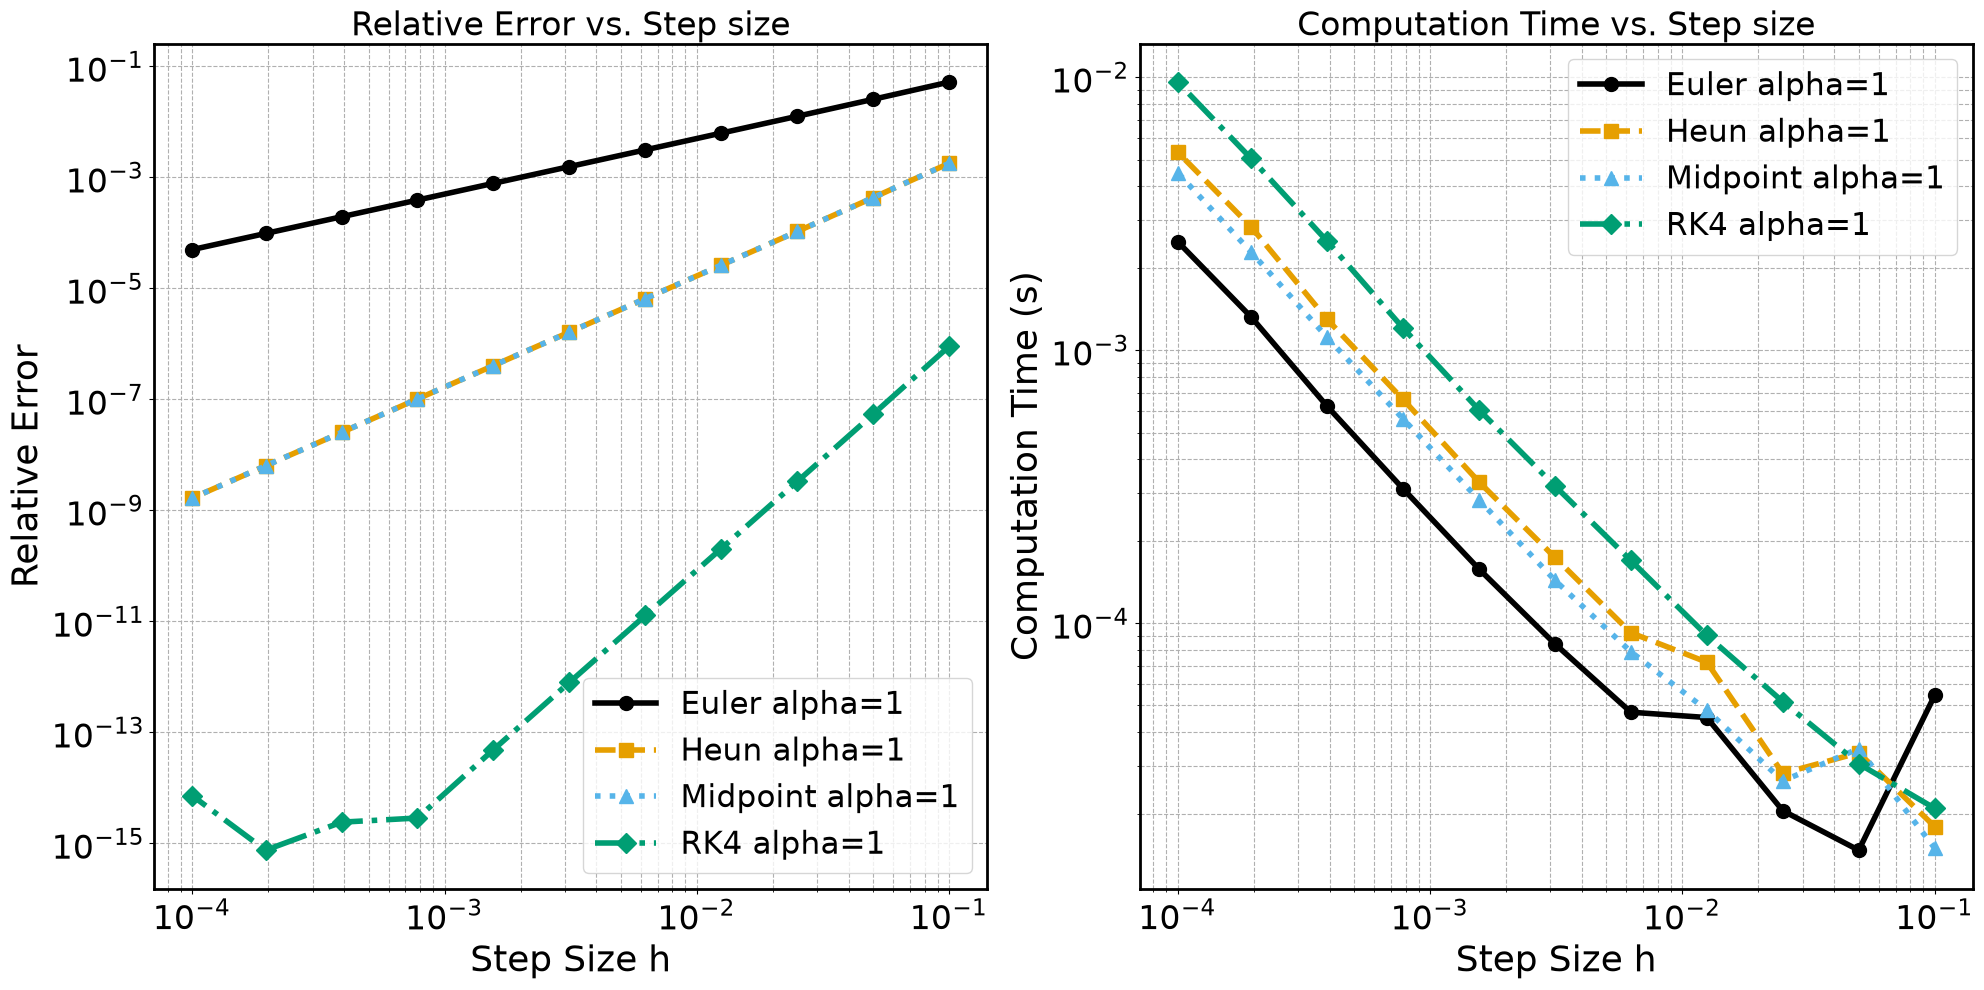

In [7]:
# Main function to execute the comparison and analysis
def main():
    # Initial conditions and settings
    y0 = 1.0
    t0 = 0.0
    t_end = 1.0
    step_sizes = [0.1, 0.05, 0.025, 0.0125, 0.00625, 0.003125, 0.0015625, 
                  0.00078125, 0.000390625, 0.0001953125, 0.0001]
    alphas = [1]  # Different alpha values for comparison
    
    # Prepare for plotting (two subplots: left for error, right for time)
    size = 10
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(2*size, size))
    
    # Define colors for different alpha values
    colors = cm.viridis(np.linspace(0, 1, len(alphas)))
    
    # Iterate over different alpha values
    for idx, alpha in enumerate(alphas):
        # Calculate the analytical solution at t_end
        y_true = analytical_solution(t_end, alpha)
        print(f"Analytical solution y({t_end}) with alpha={alpha} = {y_true:.10f}\n")
        
        # Lists to store errors and computation times for each method and step size
        euler_errors = []
        heun_errors = []
        midpoint_errors = []
        rk4_errors = []
        euler_times = []
        heun_times = []
        midpoint_times = []
        rk4_times = []
        
        # Print header
        print(f"Comparison of Methods for alpha = {alpha}:")
        print(f"{'Step Size h':>15} | {'Euler Error':>15} | {'Heun Error':>15} | {'Midpoint Error':>15} | {'RK4 Error':>15}")
        print("-" * 90)
        
        # Apply each method for every step size
        for h in step_sizes:
            # Euler Method
            start_time = time.perf_counter()
            _, y_values_euler = euler_method(f, y0, t0, t_end, h, alpha)
            end_time = time.perf_counter()
            euler_time = end_time - start_time
            euler_times.append(euler_time)
            y_euler = y_values_euler[-1]
            euler_error = abs(y_euler - y_true) / abs(y_true)
            euler_errors.append(euler_error)

            # Heun Method
            start_time = time.perf_counter()
            _, y_values_heun = rk2_heun_method(f, y0, t0, t_end, h, alpha)
            end_time = time.perf_counter()
            heun_time = end_time - start_time
            heun_times.append(heun_time)
            y_heun = y_values_heun[-1]
            heun_error = abs(y_heun - y_true) / abs(y_true)
            heun_errors.append(heun_error)

            # Midpoint Method
            start_time = time.perf_counter()
            _, y_values_midpoint = rk2_midpoint_method(f, y0, t0, t_end, h, alpha)
            end_time = time.perf_counter()
            midpoint_time = end_time - start_time
            midpoint_times.append(midpoint_time)
            y_midpoint = y_values_midpoint[-1]
            midpoint_error = abs(y_midpoint - y_true) / abs(y_true)
            midpoint_errors.append(midpoint_error)

            # RK4 Method
            start_time = time.perf_counter()
            _, y_values_rk4 = rk4_method(f, y0, t0, t_end, h, alpha)
            end_time = time.perf_counter()
            rk4_time = end_time - start_time
            rk4_times.append(rk4_time)
            y_rk4 = y_values_rk4[-1]
            rk4_error = abs(y_rk4 - y_true) / abs(y_true)
            rk4_errors.append(rk4_error)

            # Print results for each step size
            print(f"{h:15.5e} | {euler_error:15.10e} | {heun_error:15.10e} | {midpoint_error:15.10e} | {rk4_error:15.10e}")
        
        print("\n")  # Add space between different alpha values
        
                # Plot relative errors for each method on a log-log scale (left plot)
        ax1.loglog(step_sizes, euler_errors, 'o-', markersize=10, lw=4, color='#000000', label=f'Euler alpha={alpha}')
        ax1.loglog(step_sizes, heun_errors, 's--', markersize=10, lw=4, color='#E69F00', label=f'Heun alpha={alpha}')
        ax1.loglog(step_sizes, midpoint_errors, '^:', markersize=10, lw=4, color='#56B4E9', label=f'Midpoint alpha={alpha}')
        ax1.loglog(step_sizes, rk4_errors, 'D-.', markersize=10, lw=4, color='#009E73', label=f'RK4 alpha={alpha}')
        
        # Plot computation times for each method on a log-log scale (right plot)
        ax2.loglog(step_sizes, euler_times, 'o-', markersize=10, lw=4, color='#000000', label=f'Euler alpha={alpha}')
        ax2.loglog(step_sizes, heun_times, 's--', markersize=10, lw=4, color='#E69F00', label=f'Heun alpha={alpha}')
        ax2.loglog(step_sizes, midpoint_times, '^:', markersize=10, lw=4, color='#56B4E9', label=f'Midpoint alpha={alpha}')
        ax2.loglog(step_sizes, rk4_times, 'D-.', markersize=10, lw=4, color='#009E73', label=f'RK4 alpha={alpha}')
    
    # Set labels and titles for the left plot (relative error)
    ax1.set_xlabel('Step Size h')
    ax1.set_ylabel('Relative Error')
    ax1.set_title('Relative Error vs. Step size')
    ax1.grid(True, which="both", ls="--")
    
    # Set labels and titles for the right plot (computation time)
    ax2.set_xlabel('Step Size h')
    ax2.set_ylabel('Computation Time (s)')
    ax2.set_title('Computation Time vs. Step size')
    ax2.grid(True, which="both", ls="--")
    
    # Add legends
    ax1.legend()
    ax2.legend()
    
    # Display the plots
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()
